# 온라인 쇼핑 구매 여부 예측 — PyTorch 분류 미니프로젝트

**모듈 1, Day 2, 8교시 / 완료된 실습 노트북**

- **데이터:** `../data/online_shoppers_intention.csv` (`Revenue`: 구매 1 / 미구매 0)
- **개발:** pandas, scikit-learn(전처리, 기준 모델, 평가), PyTorch(MLP 구현, 학습)
- **학습 흐름:** 클래스 불균형 → 기준 모델 → MLP-A/B → 임계값 분석 → 최종 모델
- **문서:** `02_classification_data_analysis.md`, `02_classification_model_analysis.md`, 통합 `adr.md`(③, ④)

구현된 셀을 순서대로 실행합니다. Test는 과거에 확인과 모델 비교에 사용한 이력이 있으므로 독립적인 새 평가로 볼 수 없습니다. 자세한 해석은 분석 문서와 ADR을 확인합니다.

저장소 루트에서 `uv sync --locked`로 환경을 설치하고 Notebook에서 `.venv` 커널을 선택합니다.

---
## ① 데이터 탐색 및 클래스 분포 — CP-01

**목표:** 데이터 구조, 품질과 구매, 미구매 비율을 확인합니다.

### ①-1. 데이터 불러오기 — 공통 코드

In [1]:
# [공통] 패키지, 난수, 데이터 경로
import copy
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

pd.set_option("display.max_columns", 40)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cpu")
if torch.get_num_threads() > 4:
    torch.set_num_threads(4)

DATA_PATH = Path("../data/online_shoppers_intention.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError("../data/online_shoppers_intention.csv 경로를 확인하세요.")

TARGET = "Revenue"
df = pd.read_csv(DATA_PATH)
print("데이터 크기:", df.shape)
print("PyTorch:", torch.__version__, "| 장치:", DEVICE)
df.head()

데이터 크기: (12330, 18)
PyTorch: 2.15.0+cpu | 장치: cpu


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [2]:
# TODO 1-1. 컬럼 자료형과 기초 통계량을 확인합니다.
# 힌트: dtypes, describe(include="all"), display()
print("\t컬럼별 자료형\n", df.dtypes)


	컬럼별 자료형
 Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object


In [3]:
print("\t기초 통계량\n", df.describe(include="all"))

	기초 통계량
         Administrative  Administrative_Duration  Informational  \
count     12330.000000             12330.000000   12330.000000   
unique             NaN                      NaN            NaN   
top                NaN                      NaN            NaN   
freq               NaN                      NaN            NaN   
mean          2.315166                80.818611       0.503569   
std           3.321784               176.779107       1.270156   
min           0.000000                 0.000000       0.000000   
25%           0.000000                 0.000000       0.000000   
50%           1.000000                 7.500000       0.000000   
75%           4.000000                93.256250       0.000000   
max          27.000000              3398.750000      24.000000   

        Informational_Duration  ProductRelated  ProductRelated_Duration  \
count             12330.000000    12330.000000             12330.000000   
unique                     NaN             NaN  

### ①-2. 데이터 품질, 주요 특성 분포 — TODO

	컬럼별 결측값
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

중복 행 개수: 125


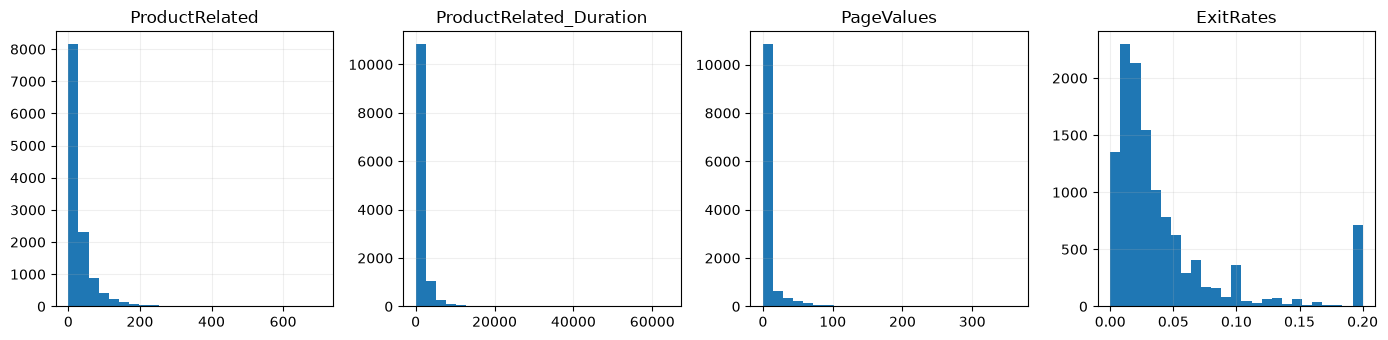

In [4]:
# TODO 1-2. 결측값 개수와 중복 행 개수를 출력합니다.
# 힌트: isna().sum(), duplicated().sum()
print("\t컬럼별 결측값")
print(df.isna().sum())
print("\n중복 행 개수:", df.duplicated().sum())

# [공통] 시각화할 특성과 그래프 틀
plot_cols = ["ProductRelated", "ProductRelated_Duration", "PageValues", "ExitRates"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col in zip(axes, plot_cols):
    # TODO 1-3. 각 특성의 히스토그램을 작성합니다.
    # 힌트: ax.hist(df[col], bins=25)
    ax.hist(df[col], bins=25)
    ax.set_title(col)
    ax.grid(alpha=0.2)
    
plt.tight_layout()
plt.show()

**그래프 읽기:** 가로축은 각 컬럼의 값, 막대 높이는 그 값의 범위에 속하는 방문 세션 수다.

- **ProductRelated (상품 페이지 방문 횟수):** 한 방문 세션에서 상품 관련 페이지를 몇 번 보았는지 나타낸다. 
10이면 상품 관련 페이지를 10회 방문한 것이다.
- **ProductRelated_Duration (상품 페이지 체류시간):** 한 방문 세션에서 상품 관련 페이지에 머문 시간을 합한 값이다. 단위는 초
- **PageValues (페이지 가치):** 방문한 페이지가 구매 등 목표 달성에 얼마나 기여했는지를 금액과 연결해 나타내는 지표다. 
상품 가격이나 해당 방문의 실제 구매 금액을 뜻하지 않는다.
- **ExitRates (종료율):** 방문한 페이지들이 다른 방문자들의 세션에서 마지막 페이지가 된 비율을 바탕으로 계산한 값이다. 
예를 들어 0.2는 방문한 페이지의 종료율을 바탕으로 계산한 지표가 20%라는 뜻이다. 전체 방문 세션 중 20%가 종료됐다는 뜻은 아니다.

**종료율과 이탈률의 차이:** 종료율은 해당 페이지를 마지막으로 방문을 끝낸 비율이고 이탈률(BounceRates)은 처음 들어온 페이지만 보고 다른 페이지로 이동하지 않은 방문의 비율이다.

**분포 해석:** 상품 페이지 방문 횟수와 체류시간, 페이지 가치는 작은 값에 세션이 몰려 있고 일부 큰 값이 오른쪽으로 길게 이어진다. 
이 그래프는 전체 분포이므로 구매 여부별 차이는 따로 비교한다.

### ①-3. 타깃 변환, 클래스 분포 — TODO

,count,rate(%)
Revenue,,
0,10422,84.53
1,1908,15.47


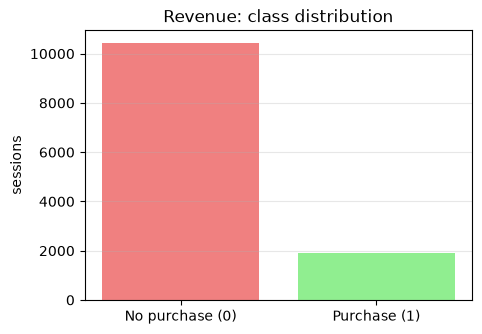

In [5]:
# TODO 1-4. Revenue와 Weekend를 0/1 정수로 변환합니다.
# 힌트: astype(int)
...
df["Revenue"] = df["Revenue"].astype(int)
df["Weekend"] = df["Weekend"].astype(int)

# TODO 1-5. Revenue의 클래스별 건수와 비율을 계산합니다.
# 힌트: value_counts().sort_index(), value_counts(normalize=True)
class_counts = df["Revenue"].value_counts().sort_index()
class_rates = df["Revenue"].value_counts(normalize=True).sort_index()

# [공통] 결과표와 그래프 틀
class_summary = pd.DataFrame({
    "count": class_counts,
    "rate(%)": (class_rates * 100).round(2),
})
display(class_summary)

plt.figure(figsize=(5, 3.5))
# TODO 1-6. 구매, 미구매 건수를 막대그래프로 시각화합니다.
# 힌트: plt.bar([...], class_counts.values)
plt.bar(["No purchase (0)", "Purchase (1)"], class_counts.values, color=["lightcoral", "lightgreen"])
plt.ylabel("sessions")
plt.title("Revenue: class distribution")
plt.grid(axis="y", alpha=0.3)
plt.show()

**결과 해석:** `Revenue=0`은 구매하지 않은 방문, `Revenue=1`은 구매한 방문이다. 전체 12,330건 중 미구매는 10,422건(84.53%), 구매는 1,908건(15.47%)이다. 그래프의 막대 높이는 각 방문 세션의 건수를 나타낸다.

**클래스 불균형:** 구매한 세션이 미구매 세션보다 훨씬 적다. 모든 세션을 미구매로 예측해도 정확도는 84.53%지만, 실제 구매는 한 건도 찾아내지 못한다. 따라서 정확도뿐 아니라 구매를 얼마나 찾아냈는지 재현율과 정밀도, F1도 함께 확인한다.

**[CP-01] 완료 기준:** 데이터 크기, 결측값, 중복 행과 구매 클래스 비율 및 분포 그래프를 확인합니다.



---
## ② 계층화 데이터 분할 및 특성 분석 — CP-02

**목표:** 구매 비율을 유지해 데이터를 분리하고 Train의 주요 특성을 비교합니다.

### ②-1. 입력, 정답 구분과 계층화 분할 — TODO

In [6]:
from sklearn.model_selection import train_test_split

# TODO 2-1. Revenue를 제외한 입력 특성 FEATURES, X, y를 작성합니다.
FEATURES = [col for col in df.columns if col != "Revenue"]
X = df[FEATURES]
y = df["Revenue"]

# TODO 2-2. stratify를 사용하여 Train 70%, Validation 15%, Test 15%로 나눕니다.
# 1) 전체 데이터의 15%를 Test로 분리
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.15,
    stratify=y,
    random_state=SEED,
)
# 2) 나머지에서 0.15/0.85 비율을 Validation으로 분리
# random_state=SEED를 두 번 모두 지정합니다.
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev,
    test_size=0.15 / 0.85,
    stratify=y_dev,
    random_state=SEED,
)

# [공통] 분할 검증
for name, xx, yy in [
    ("Train", X_train, y_train),
    ("Validation", X_valid, y_valid),
    ("Test", X_test, y_test),
]:
    print(f"{name:<11} rows={len(xx):>5}  purchase_rate={yy.mean():.2%}")

assert len(X_train) + len(X_valid) + len(X_test) == len(df)
assert set(X_train.index).isdisjoint(X_valid.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_valid.index).isdisjoint(X_test.index)

Train       rows= 8630  purchase_rate=15.48%
Validation  rows= 1850  purchase_rate=15.46%
Test        rows= 1850  purchase_rate=15.46%


**결과 해석:** Test 15%를 제외한 나머지 85%에서 전체의 15%를 Validation으로 떼기 위해 `0.15 / 0.85`를 사용. 
세 집합의 구매 비율은 약 15.5%로 유지됐다.

### ②-2. 방문자 유형별 구매율 — TODO

,sessions,purchase_rate
VisitorType,,
New_Visitor,1162,0.252151
Other,63,0.158730
Returning_Visitor,7405,0.139500


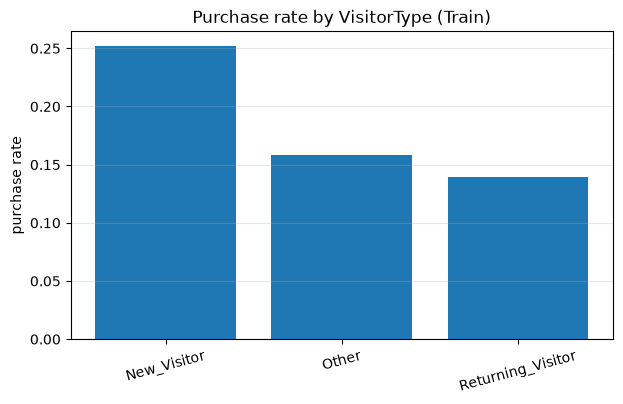

In [7]:
# [공통] Train 데이터만 활용한 특성 분석
train_view = X_train.copy()
train_view[TARGET] = y_train

# TODO 2-3. VisitorType별 세션 수(sessions)와 구매율(purchase_rate)을 계산합니다.
# 힌트: groupby(), agg(), sort_values()
visitor_rate = (
    train_view.groupby("VisitorType")[TARGET]
    .agg(sessions="count", purchase_rate="mean")
    .sort_values("purchase_rate", ascending=False)
)
display(visitor_rate)

plt.figure(figsize=(7, 4))
# TODO 2-4. 방문자 유형별 구매율을 막대그래프로 나타냅니다.
# 힌트: plt.bar(visitor_rate.index.astype(str), visitor_rate["purchase_rate"])
plt.bar(visitor_rate.index.astype(str), visitor_rate["purchase_rate"])
plt.ylabel("purchase rate")
plt.title("Purchase rate by VisitorType (Train)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.show()

**결과 해석:** Train에서 신규 방문자(New_Visitor)는 1,162건 중 약 25.22%가 구매했고, 재방문자(Returning_Visitor)는 7,405건 중 약 13.95%가 구매했다. 기타(Other)는 63건 중 약 15.87%가 구매했다.

**해석:** 이번 Train 데이터에서는 신규 방문의 구매율이 가장 높았고, 재방문의 세션 수가 가장 많았다. 기타 유형은 63건으로 적어 몇 건의 구매 차이에도 비율이 크게 달라질 수 있다. 이 결과만으로 방문 유형이 구매의 원인이라고 단정할 수는 없다.

### ②-3. 클래스별 행동 특성 중앙값 — TODO

In [8]:
# [공통] 구매, 미구매 클래스별 비교 특성
compare_cols = ["ProductRelated", "ProductRelated_Duration", "PageValues", "ExitRates"]

# TODO 2-5. Revenue별 compare_cols 중앙값을 계산합니다.
# 힌트: groupby(TARGET)[compare_cols].median()
median_by_class = train_view.groupby(TARGET)[compare_cols].median()

# [공통] 결과 표시
median_by_class.index = ["미구매 (0)", "구매 (1)"]
display(median_by_class.round(3))

,ProductRelated,ProductRelated_Duration,PageValues,ExitRates
미구매 (0),16.0,517.580,0.000,0.029
구매 (1),29.0,1069.658,17.543,0.015


**결과 해석:** 각 값은 Train의 구매, 미구매 그룹을 따로 정렬했을 때 가운데에 있는 값이다.

- **상품 페이지 방문 횟수:** 미구매 16회, 구매 29회로 구매 그룹이 더 많았다.
- **상품 페이지 체류시간:** 미구매 약 518초, 구매 약 1,070초로 구매 그룹이 더 길었다.
- **페이지 가치:** 미구매 0, 구매 약 17.543으로 구매 그룹이 더 높았다.
- **종료율:** 미구매 약 2.9%, 구매 약 1.5%로 구매 그룹이 방문한 페이지의 종료율이 더 낮았다.

**해석:** 이번 Train 데이터에서 구매 그룹은 상품 페이지를 더 많이 보고 오래 머무는 경향이 있었다. 그룹의 중앙값 비교이므로 모든 방문에 적용되거나 구매의 원인이라고 단정할 수 없다. 페이지 가치는 구매 등 목표 달성과 관련된 값이므로 방문 초기에 사용할 수 있는지는 별도로 확인해야 한다.

**[CP-02] 완료 기준:** Train, Validation, Test의 구매 비율과 Train 특성별 구매율, 중앙값을 확인합니다.

---
## ③ 데이터 전처리 및 Tensor 준비 — CP-03

**목표:** 전처리 결과를 PyTorch가 학습할 수 있는 Tensor, DataLoader로 만듭니다.
**이유:** 모델이 종류를 크기로 오해하지 않도록 범주형 값을 나누고, 수치형은 크기 차이를 줄인다. 변환 기준은 Train으로 학습한다.


### ③-1. 범주형, 수치형, 이진형 구분 — TODO

In [9]:
# TODO 3-1. FEATURES를 범주형, 수치형, 이진형으로 구분합니다.
# 범주형: Month, OperatingSystems, Browser, Region, TrafficType, VisitorType
# 수치형: 페이지 횟수, 체류시간, BounceRates, ExitRates, PageValues, SpecialDay
# 이진형: Weekend
categorical_features = [
    # 범주형 컬럼 이름
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
]

numeric_features = [
    # 수치형 컬럼 이름
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
]

binary_features = [
    # 이진형 컬럼 이름
    "Weekend",
]

# [공통] 컬럼 목록 검사
assert set(categorical_features + numeric_features + binary_features) == set(FEATURES)
assert len(categorical_features + numeric_features + binary_features) == len(FEATURES)
print("특성 개수:", len(FEATURES))

특성 개수: 17


**결과 해석:** 입력 특성 17개를 범주형 6개, 수치형 10개, 이진형 1개로 나눴다. 검사 코드를 통과해 빠지거나 중복된 특성이 없음을 확인했다.

### ③-2. One-Hot 인코딩, 표준화, ColumnTransformer — TODO

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_preprocessor():
    # TODO 3-2. 범주형 OneHotEncoder, 수치형 StandardScaler,
    # 이진형 passthrough를 ColumnTransformer로 결합합니다.
    # OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([
        ("category", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ), categorical_features),
        ("numeric", StandardScaler(), numeric_features),
        ("binary", "passthrough", binary_features),
    ])

preprocessor = make_preprocessor()

# TODO 3-3. Train으로 전처리를 학습하고 Validation에 동일한 변환을 적용합니다.
# 힌트: fit_transform(), transform(), np.asarray(..., dtype=np.float32)
Xt_train = np.asarray(
    preprocessor.fit_transform(X_train),
    dtype=np.float32,
)
Xt_valid = np.asarray(
    preprocessor.transform(X_valid),
    dtype=np.float32,
)

# [공통] Shape와 유한값 검사
print("변환 전:", X_train.shape)
print("변환 후 Train:", Xt_train.shape, "/ Valid:", Xt_valid.shape)
assert Xt_train.shape[1] == Xt_valid.shape[1]
assert np.isfinite(Xt_train).all() and np.isfinite(Xt_valid).all()

변환 전: (8630, 17)
변환 후 Train: (8630, 73) / Valid: (1850, 73)


**결과 해석:** 원-핫 인코딩으로 범주형 특성이 여러 0/1 열로 펼쳐져 입력 열이 17개에서 73개가 됐다. Train과 Validation에 Train에서 학습한 같은 기준을 적용해 두 데이터의 열 구조가 일치한다.

### ③-3. Tensor 변환, DataLoader — TODO

In [11]:
# TODO 3-4. 전처리된 입력과 타깃을 PyTorch float32 Tensor로 바꿉니다.
# 힌트: torch.from_numpy(), torch.tensor(..., dtype=torch.float32)
x_train_tensor = torch.from_numpy(Xt_train)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32)

x_valid_tensor = torch.from_numpy(Xt_valid)
y_valid_tensor = torch.tensor(y_valid.to_numpy(), dtype=torch.float32)

# TODO 3-5. 학습용 TensorDataset과 DataLoader를 만듭니다.
# batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(SEED)
train_ds = TensorDataset(x_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_ds,
    batch_size=256,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)

# [공통] Tensor 형식과 배치 개수 확인
print("Tensor:", x_train_tensor.shape, y_train_tensor.shape)
print("\ndtype:", x_train_tensor.dtype, y_train_tensor.dtype)
print("\nMini-batches:", len(train_loader))

Tensor: torch.Size([8630, 73]) torch.Size([8630])

dtype: torch.float32 torch.float32

Mini-batches: 34


**결과 해석:** Train의 8,630개 입력과 정답을 각각 float32 Tensor로 준비했다. 256건씩 나눈 미니배치는 34개이며 마지막 배치에는 남은 182건이 들어간다.

**[CP-03] 완료 기준:** Train 기반 전처리, `float32` Tensor 변환, 미니배치 생성과 입력 Shape를 확인합니다.

---
## ④ 기준 모델 및 Logistic Regression — CP-04

**목표:** 기준 모델을 학습하고 Accuracy, Precision, Recall, F1을 비교합니다.

### ④-1. Dummy, Logistic Regression 학습 — TODO

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression


# [공통] sklearn 모델 + 전처리 Pipeline

def make_sklearn_pipeline(estimator):
    return Pipeline([
        ("prep", make_preprocessor()),
        ("model", estimator),
    ])


# TODO 4-1. DummyClassifier(strategy="most_frequent")와
# LogisticRegression(max_iter=1500)을 Pipeline으로 구성합니다.
dummy_model = make_sklearn_pipeline(
    DummyClassifier(strategy="most_frequent")
)

logistic_model = make_sklearn_pipeline(
    LogisticRegression(max_iter=1500)
)

# [공통] 두 모델 학습
dummy_model.fit(X_train, y_train)
logistic_model.fit(X_train, y_train)
print("학습 완료")

학습 완료


### ④-2. 분류 평가 함수, 모델 비교 — TODO

In [13]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
)


def classification_scores(y_true, y_pred):
    """구매 클래스(1) 기준 지표를 반환합니다."""
    # TODO 4-2. Accuracy, Precision, Recall, F1을 계산합니다.
    # Precision, Recall, F1은 zero_division=0으로 설정합니다.
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }
 

# [공통] sklearn/MLP 모델 모두 사용할 결과 정리 함수
def summary_row(name, train_true, train_pred, valid_true, valid_pred):
    tr = classification_scores(train_true, train_pred)
    va = classification_scores(valid_true, valid_pred)
    return {
        "Model": name,
        **{f"Train {k}": v for k, v in tr.items()},
        **{f"Valid {k}": v for k, v in va.items()},
    }


# TODO 4-3. 두 기준 모델의 Train, Validation 예측값을 사용하여
# summary_row() 결과를 results 리스트에 저장합니다.
results = [
    # summary_row("DummyClassifier", ...),
    # summary_row("LogisticRegression", ...),
    summary_row(
        "DummyClassifier",
        y_train, dummy_model.predict(X_train),
        y_valid, dummy_model.predict(X_valid),
    ),
    summary_row(
        "LogisticRegression",
        y_train, logistic_model.predict(X_train),
        y_valid, logistic_model.predict(X_valid),
    ),
]

display(pd.DataFrame(results).round(3))

,Model,Train Accuracy,Train Precision,Train Recall,Train F1,Valid Accuracy,Valid Precision,Valid Recall,Valid F1
0,DummyClassifier,0.845,0.000,0.000,0.000,0.845,0.000,0.000,0.00
1,LogisticRegression,0.884,0.747,0.382,0.505,0.882,0.734,0.367,0.49


**결과 해석: Validation 데이터, 구매 클래스(1) 기준**

1. **Accuracy, 정확도:** 전체 방문 중 구매 여부를 맞힌 비율이다. LogisticRegression은 **88.2%**, DummyClassifier는 **84.5%**다.
2. **Precision, 정밀도:** 구매라고 예측한 방문 중 실제 구매한 비율이다. LogisticRegression은 **73.4%**다. DummyClassifier는 구매라고 예측하지 않아 계산할 수 없는 값을 설정에 따라 0으로 표시했다.
3. **Recall, 재현율:** 실제 구매한 방문 중 구매라고 맞힌 비율이다. LogisticRegression은 **36.7%**를 찾아냈고, DummyClassifier는 **0%**다.
4. **F1 점수:** 정밀도와 재현율의 조화평균으로 두 지표를 함께 본다. LogisticRegression은 **0.490 (49.0%)**, DummyClassifier는 **0**이다.

**비교:** DummyClassifier는 모두 미구매로 예측해 정확도는 84.5%지만 실제 구매를 찾아내지 못했다. LogisticRegression은 실제 구매의 36.7%를 찾아냈지만 나머지 약 63.3%는 놓쳤다.

### ④-3. 혼동행렬 — TODO

In [14]:
# TODO 4-4. LogisticRegression의 Validation 예측값을 생성합니다.
logistic_pred = logistic_model.predict(X_valid)

# TODO 4-5. confusion_matrix(..., labels=[0, 1])로 혼동행렬을 만듭니다.
logistic_cm = logistic_cm = confusion_matrix(
    y_valid,
    logistic_pred,
    labels=[0, 1],
)

# [공통] 결과 출력
logistic_cm = pd.DataFrame(
    logistic_cm,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"],
)
display(logistic_cm)
print(classification_report(y_valid, logistic_pred, zero_division=0))

,Predicted 0,Predicted 1
Actual 0,1526,38
Actual 1,181,105


              precision    recall  f1-score   support

           0       0.89      0.98      0.93      1564
           1       0.73      0.37      0.49       286

    accuracy                           0.88      1850
   macro avg       0.81      0.67      0.71      1850
weighted avg       0.87      0.88      0.86      1850



**혼동행렬 해석:** 행은 실제 결과, 열은 모델의 예측이다. 0은 미구매, 1은 구매를 뜻한다.

- **1,526건 (TN):** 실제 미구매를 미구매로 맞혔다.
- **38건 (FP):** 실제 미구매인데 구매로 잘못 예측했다.
- **181건 (FN):** 실제 구매인데 미구매로 잘못 예측했다.
- **105건 (TP):** 실제 구매를 구매로 맞혔다.

**구매 클래스 평가:** 실제 구매 286건 중 105건을 찾아 재현율은 약 36.7%이고, 구매로 예측한 143건 중 105건이 실제 구매여서 정밀도는 약 73.4%다. 전체 1,850건 중 1,631건을 맞혀 정확도는 약 88.2%지만, 실제 구매 181건을 놓쳤다.

**분류 보고서:** `support`는 각 클래스의 실제 건수로, 미구매 1,564건과 구매 286건이다. 보고서의 0행과 1행은 각각 미구매와 구매를 기준으로 계산한 지표다.

**[CP-04] 완료 기준:** 두 모델의 성능표와 혼동행렬을 완성합니다.

**의사결정 ③:** 불균형 데이터에서 우선할 지표를 `adr.md`에 기록합니다.

### CP-04 선택 실험 — 로지스틱 회귀 설정과 임계값 비교

**문제:** 기본 모델은 Validation에서 실제 구매 286건 중 181건을 놓쳤다. 설정을 바꾸면 구매를 더 잘 찾아낼 수 있는지 확인한다.

**방법:** `C`를 0.1, 1, 10으로 바꾸고 클래스 가중치 기본값과 `balanced`를 비교한다. 각 설정은 Train으로만 학습하고, Validation에서 임계값 0.3, 0.5, 0.7을 적용해 정확도, 정밀도, 재현율, F1, FP와 FN을 비교한다. FP는 미구매를 구매로 잘못 예측한 수, FN은 실제 구매를 놓친 수다. Test는 이 실험에 사용하지 않는다.

`C`가 작을수록 규제가 강하고 `balanced`는 적은 클래스에 더 높은 가중치를 준다. 임계값 변경은 학습된 모델의 구매 확률을 0과 1로 나누는 기준을 바꾸며 모델을 다시 학습하지 않는다.


In [15]:
# 선택 실험: 로지스틱 회귀의 규제, 클래스 가중치, 임계값 비교
logistic_experiments = []
for c_value in [0.1, 1.0, 10.0]:
    for weight in [None, "balanced"]:
        model = make_sklearn_pipeline(
            LogisticRegression(C=c_value, class_weight=weight, max_iter=1500)
        )
        model.fit(X_train, y_train)
        valid_prob = model.predict_proba(X_valid)[:, 1]
        for threshold in [0.3, 0.5, 0.7]:
            pred = (valid_prob >= threshold).astype(int)
            tn, fp, fn, tp = confusion_matrix(y_valid, pred, labels=[0, 1]).ravel()
            logistic_experiments.append({
                "C": c_value, "class_weight": "기본" if weight is None else "balanced",
                "threshold": threshold, **classification_scores(y_valid, pred),
                "FP": int(fp), "FN": int(fn),
            })
logistic_experiment_df = pd.DataFrame(logistic_experiments)
display(logistic_experiment_df.round(3))


,C,class_weight,threshold,Accuracy,Precision,Recall,F1,FP,FN
0,0.1,기본,0.3,0.891,0.702,0.510,0.591,62,140
1,0.1,기본,0.5,0.881,0.734,0.357,0.480,37,184
2,0.1,기본,0.7,0.874,0.771,0.259,0.387,22,212
3,0.1,balanced,0.3,0.712,0.341,0.930,0.500,513,20
4,0.1,balanced,0.5,0.858,0.529,0.731,0.614,186,77
5,0.1,balanced,0.7,0.895,0.700,0.563,0.624,69,125
6,1.0,기본,0.3,0.891,0.702,0.510,0.591,62,140
7,1.0,기본,0.5,0.882,0.734,0.367,0.490,38,181
8,1.0,기본,0.7,0.875,0.776,0.266,0.396,22,210
9,1.0,balanced,0.3,0.715,0.341,0.906,0.495,501,27


**결과 해석:** 기존 설정(`C=1`, 기본 가중치, 임계값 0.5)의 Validation 정밀도는 0.734, 재현율은 0.367, F1은 0.490이며 FP 38건, FN 181건이다.

비교한 18개 조합 중 F1이 가장 높은 설정은 `C=0.1`, `balanced`, 임계값 0.7이다. 정밀도 0.700, 재현율 0.563, F1 0.624이며 FP 69건, FN 125건이다. 기존 설정보다 구매를 56건 더 찾아냈지만, 실제 미구매를 구매로 잘못 예측한 경우도 31건 늘었다.

**판단과 한계:** 가중치와 임계값에 따라 구매를 찾는 비율과 잘못 구매로 판단하는 수가 달라진다. 여러 조합을 같은 Validation에서 비교했으므로 최고 점수가 다른 데이터에서도 유지된다고 단정할 수 없다. 로지스틱 회귀를 비교 기준으로 활용하고, 이어지는 MLP 실험과 가중치 조정 결과까지 함께 살펴 최종 모델을 선택한다.


---
## ⑤ PyTorch MLP-A 구현 및 학습 — CP-05

**목표:** 신경망 구조와 순전파, 손실, 역전파, 가중치 갱신을 구현합니다.
**이유:** 로지스틱 회귀에 이어 여러 특성 사이의 복잡한 관계도 학습할 수 있는 신경망을 비교한다. 먼저 구매 가중치를 주지 않는 MLP-A를 기준으로 학습한다.


### ⑤-1. MLP 구조, 구매 확률 함수 — TODO

In [16]:
# TODO 5-1. 입력 → 은닉층 64 → 은닉층 32 → 출력 1인 MLP를 구현합니다.
# 은닉층: Linear + ReLU, 첫 은닉층에는 Dropout(dropout) 적용
# 마지막 출력: Sigmoid 없이 logits(원시 점수) 반환
class PurchaseMLP(nn.Module):
    def __init__(self, input_dim, dropout=0.1):
        super().__init__()
        self.network = nn.Sequential(
            # nn.Linear(input_dim, 64), ...,
            nn.Linear(input_dim, 64),  # 입력 → 은닉층 64개
            nn.ReLU(),                 # 비선형 활성화
            nn.Dropout(dropout),       # 일부 출력을 무작위로 제외
            nn.Linear(64, 32),         # 은닉층 64개 → 32개
            nn.ReLU(),                 # 비선형 활성화
            nn.Linear(32, 1),          # 최종 점수 1개
        )

    def forward(self, x):
        # TODO 5-2. 마지막 출력의 크기를 (batch,)로 맞춥니다.
        # 힌트: self.network(x).squeeze(1)
        return self.network(x).squeeze(1)  # (batch, 1) → (batch,)


# [공통] 모델의 logits를 구매 확률로 변환하는 함수 틀
def mlp_probabilities(model, X_scaled):
    model.eval()
    tensor = torch.from_numpy(np.asarray(X_scaled, dtype=np.float32))
    with torch.no_grad():
        # TODO 5-3. logits를 구하고 Sigmoid를 적용해 NumPy 배열로 반환합니다.
        # 힌트: torch.sigmoid(...).cpu().numpy()
        logits = model(tensor.to(DEVICE))              # 원시 점수 계산
        return torch.sigmoid(logits).cpu().numpy()     # 확률로 변환


# [공통] 초기화, 생성 코드
def make_mlp(input_dim):
    torch.manual_seed(SEED)
    return PurchaseMLP(input_dim=input_dim, dropout=0.1).to(DEVICE)


# [공통] 신경망 출력 형태 확인
probe = make_mlp(Xt_train.shape[1])
print(probe)
print("샘플 4건의 logits:", probe(x_train_tensor[:4]).detach().numpy())

PurchaseMLP(
  (network): Sequential(
    (0): Linear(in_features=73, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=1, bias=True)
  )
)
샘플 4건의 logits: [-0.06033622 -0.08261517 -0.04338983 -0.05742761]


### ⑤-2. 미니배치 학습, 검증 함수 — TODO

In [17]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    """미니배치별 학습을 한 에포크 수행합니다."""
    model.train()
    losses = []
    for xb, yb in loader:
        # TODO 5-4. 기울기 초기화 → 순전파(logits) → 손실 계산 →
        # 역전파 → 가중치 갱신을 순서대로 구현합니다.
        # 힌트: zero_grad(), model(xb), loss_fn(), backward(), step()
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)  # 배치를 학습 장치로 이동
        optimizer.zero_grad()             # 이전 기울기 초기화
        logits = model(xb)                # 순전파로 점수 계산
        loss = loss_fn(logits, yb)        # 예측 점수와 정답의 손실
        loss.backward()                   # 역전파로 기울기 계산
        optimizer.step()                  # 가중치 갱신
        losses.append(float(loss.item()))
    return float(np.mean(losses))


def fit_mlp(Xtr, ytr, Xva, yva, *, positive_weight=None, epochs=25):
    """Validation F1 최고 에포크의 모델을 반환합니다."""
    # [공통] 모델, DataLoader, 최고 검증 점수 기록 준비
    torch.manual_seed(SEED)
    model = make_mlp(Xtr.shape[1])
    loader = DataLoader(
        TensorDataset(
            torch.from_numpy(np.asarray(Xtr, dtype=np.float32)),
            torch.tensor(np.asarray(ytr), dtype=torch.float32),
        ),
        batch_size=256,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

    # TODO 5-5. positive_weight가 None이면 일반 BCEWithLogitsLoss(),
    # 값이 있으면 pos_weight를 적용한 BCEWithLogitsLoss를 사용합니다.
    # 힌트: nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(positive_weight)))
    if positive_weight is None:
        loss_fn = nn.BCEWithLogitsLoss()  # 기본 BCE 손실
    else:
        weight = torch.tensor(float(positive_weight), dtype=torch.float32, device=DEVICE)  # 양성 클래스 가중치를 Tensor로 변환
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=weight)  # 구매 손실에 가중치 적용

    # TODO 5-6. Adam 옵티마이저(lr=0.001)를 생성합니다.
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)  # 가중치 갱신

    # [공통] Validation F1이 가장 좋았던 에포크의 가중치 보관
    history = []
    best_f1 = -1.0
    best_epoch = 1
    best_state = None

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, loader, loss_fn, optimizer)
        train_prob = mlp_probabilities(model, Xtr)
        valid_prob = mlp_probabilities(model, Xva)

        # TODO 5-7. 확률 0.5 기준 예측 클래스를 만든 후
        # classification_scores()로 Train, Validation F1을 계산합니다.
        tr_pred = (train_prob >= 0.5).astype(int)  # Train 확률을 0/1로 변환
        va_pred = (valid_prob >= 0.5).astype(int)  # Validation에도 같은 기준 적용
        tr_f1 = classification_scores(ytr, tr_pred)["F1"]  # Train F1 계산
        va_f1 = classification_scores(yva, va_pred)["F1"]  # Validation F1 계산

        # [공통] 학습 이력과 최고 검증 성능 기록
        history.append({
            "Epoch": epoch, "Train loss": train_loss,
            "Train F1": tr_f1, "Valid F1": va_f1,
        })
        if va_f1 > best_f1:
            best_f1 = va_f1
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), best_epoch

### ⑤-3. MLP-A 학습, 학습 곡선 — TODO

MLP-A 최고 Validation F1 에포크: 25


,Epoch,Train loss,Train F1,Valid F1
20,21,0.217,0.691,0.618
21,22,0.217,0.681,0.619
22,23,0.215,0.706,0.632
23,24,0.213,0.694,0.621
24,25,0.212,0.709,0.633


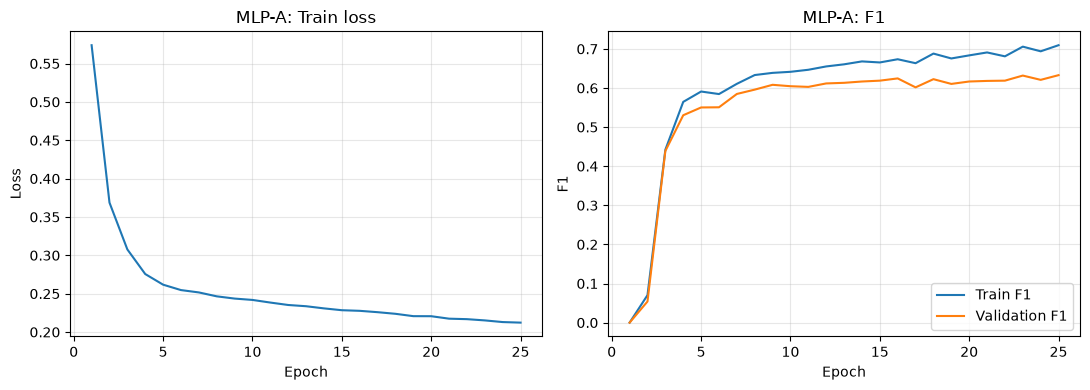

In [18]:
# [공통] MLP-A: 클래스 가중치 없는 기본 BCE 학습
EPOCHS = 25
mlp_a, history_a, best_epoch_a = fit_mlp(
    Xt_train, y_train.to_numpy(), Xt_valid, y_valid.to_numpy(),
    positive_weight=None, epochs=EPOCHS,
)
print("MLP-A 최고 Validation F1 에포크:", best_epoch_a)
display(history_a.tail().round(3))

# TODO 5-8. Epoch별 Train loss, Train/Validation F1을 시각화합니다.
# 힌트: plt.subplots(1, 2, ...), ax.plot(history_a["Epoch"], ...)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))  # 그래프 2개 생성
axes[0].plot(history_a["Epoch"], history_a["Train loss"], label="Train loss")  # 에포크별 학습 손실 표시
axes[0].set_xlabel("Epoch")  # 가로축 이름
axes[0].set_ylabel("Loss")  # 세로축 이름
axes[0].set_title("MLP-A: Train loss")  # 손실 그래프 제목
axes[0].grid(alpha=0.3)  # 격자 표시
axes[1].plot(history_a["Epoch"], history_a["Train F1"], label="Train F1")  # Train F1 표시
axes[1].plot(history_a["Epoch"], history_a["Valid F1"], label="Validation F1")  # Validation F1 표시
axes[1].set_xlabel("Epoch")  # 가로축 이름
axes[1].set_ylabel("F1")  # 세로축 이름
axes[1].set_title("MLP-A: F1")  # F1 그래프 제목
axes[1].legend()  # 범례 표시
axes[1].grid(alpha=0.3)  # 격자 표시
plt.tight_layout()  # 그래프 간격 정리
plt.show()  # 그래프 출력


**결과 해석:** MLP-A는 25에포크 중 25번째에서 Validation F1이 가장 높았다. 해당 에포크의 Train F1은 0.709, Validation F1은 0.633이다.

**학습 곡선:** Train loss는 첫 에포크 0.574에서 마지막 에포크 0.212로 변했다. 손실이 줄어드는 것과 검증 F1이 계속 좋아지는 것은 다르므로, 최고 검증 F1의 가중치를 보관해 다음 실험에서 비교한다. 이 결과는 임계값 0.5와 이번 Validation 분할에서의 결과다.

**[CP-05] 완료 기준:** MLP-A의 logits, 손실, 학습 과정과 Train loss, F1 곡선을 확인합니다.

---
## ⑥ MLP-B 개선 및 모델 성능 비교 — CP-06

**목표:** 양성 클래스 가중 손실을 적용하고 MLP-A/B 성능을 비교합니다.
**이유:** 구매 사례가 적어 모델이 구매를 놓칠 수 있으므로 구매 사례의 손실에 가중치를 주고, 구매를 더 잘 찾는지 MLP-A와 비교한다.


### ⑥-1. 클래스 가중 손실 적용 — TODO

In [19]:
# TODO 6-1. Train에서 미구매, 구매 건수를 구하고 pos_weight를 계산합니다.
# 힌트: pos_weight = 미구매 수 / 구매 수
n_negative = int((y_train == 0).sum())  # Train의 미구매 세션 수
n_positive = int((y_train == 1).sum())  # Train의 구매 세션 수
pos_weight = n_negative / n_positive  # 구매 손실에 적용할 가중치
print("Train 불균형 비율(neg/pos):", round(pos_weight, 3))

# [공통] MLP-B: 가중 BCE 학습
mlp_b, history_b, best_epoch_b = fit_mlp(
    Xt_train, y_train.to_numpy(), Xt_valid, y_valid.to_numpy(),
    positive_weight=pos_weight, epochs=EPOCHS,
)
print("MLP-B 최고 Validation F1 에포크:", best_epoch_b)
display(history_b.tail().round(3))

Train 불균형 비율(neg/pos): 5.46
MLP-B 최고 Validation F1 에포크: 17


,Epoch,Train loss,Train F1,Valid F1
20,21,0.512,0.680,0.622
21,22,0.501,0.692,0.631
22,23,0.502,0.667,0.608
23,24,0.496,0.680,0.615
24,25,0.490,0.685,0.616


**결과 해석:** Train의 미구매는 7,294건, 구매는 1,336건으로 구매 손실에 적용한 가중치 `pos_weight`는 약 5.460이다. MLP-B는 25에포크 중 17번째에서 임계값 0.5 기준 Validation F1이 가장 높았다.

**의미:** 구매 사례의 손실에 더 큰 비중을 주고 학습한다. 가중치를 적용해도 실제로 성능이 좋아졌는지는 아래 검증 결과에서 확인한다.


### ⑥-2. 학습 곡선, 전체 모델 비교 — TODO

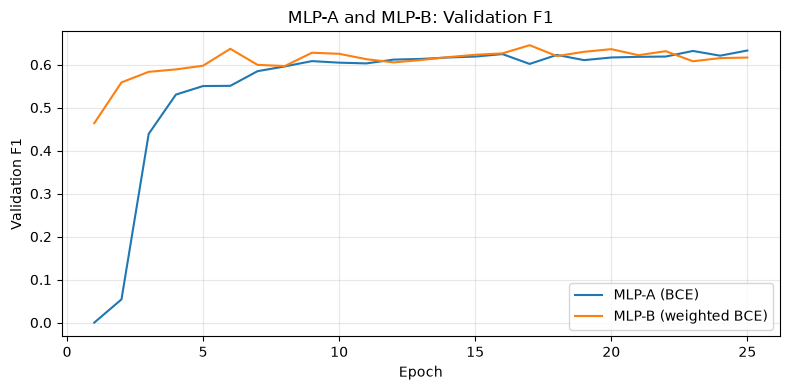

,Model,Train Accuracy,Train Precision,Train Recall,Train F1,Valid Accuracy,Valid Precision,Valid Recall,Valid F1,Gap (Train-Valid F1)
0,MLP-B (weighted BCE),0.884,0.588,0.841,0.692,0.875,0.575,0.734,0.645,0.047
1,MLP-A (BCE),0.914,0.743,0.679,0.709,0.898,0.717,0.566,0.633,0.077
2,LogisticRegression,0.884,0.747,0.382,0.505,0.882,0.734,0.367,0.490,0.016
3,DummyClassifier,0.845,0.000,0.000,0.000,0.845,0.000,0.000,0.000,0.000


In [20]:
# TODO 6-2. MLP-A와 MLP-B의 Epoch별 Validation F1 곡선을 비교합니다.
# 힌트: history_a, history_b, plt.plot()
plt.figure(figsize=(8, 4))  # 그래프 크기 지정
plt.plot(history_a["Epoch"], history_a["Valid F1"], label="MLP-A (BCE)")  # 기본 손실 F1
plt.plot(history_b["Epoch"], history_b["Valid F1"], label="MLP-B (weighted BCE)")  # 가중 손실 F1
plt.xlabel("Epoch")  # 가로축: 학습 횟수
plt.ylabel("Validation F1")  # 세로축: 검증 F1
plt.title("MLP-A and MLP-B: Validation F1")  # 그래프 제목
plt.grid(alpha=0.3)  # 격자 표시
plt.legend()  # 모델별 범례 표시
plt.tight_layout()  # 그래프 간격 정리
plt.show()  # 그래프 출력

# [공통] 두 신경망 및 선택 에포크 보관
mlp_models = {
    "MLP-A (BCE)": mlp_a,
    "MLP-B (weighted BCE)": mlp_b,
}
mlp_best_epochs = {
    "MLP-A (BCE)": best_epoch_a,
    "MLP-B (weighted BCE)": best_epoch_b,
}

# TODO 6-3. 두 MLP의 Train, Validation 구매 확률을 계산하고
# 기본 임계값 0.5로 분류한 뒤, summary_row() 결과를 results에 추가합니다.
results = [row for row in results if row["Model"] not in mlp_models]  # 재실행 시 기존 MLP 결과 제거
for name, model in mlp_models.items():
    tr_pred = (mlp_probabilities(model, Xt_train) >= 0.5).astype(int)  # Train 구매 예측
    va_pred = (mlp_probabilities(model, Xt_valid) >= 0.5).astype(int)  # Validation 구매 예측
    results.append(summary_row(name, y_train, tr_pred, y_valid, va_pred))

# TODO 6-4. 모델별 Valid F1 내림차순 정렬 및 Train-Valid F1 차이 계산
results_df = pd.DataFrame(results).sort_values("Valid F1", ascending=False).reset_index(drop=True)  # 검증 F1순 정렬
results_df["Gap (Train-Valid F1)"] = results_df["Train F1"] - results_df["Valid F1"]  # 훈련과 검증 차이
display(results_df.round(3))

**결과 해석:** 기본 임계값 0.5에서 MLP-A의 Validation Precision, Recall, F1은 각각 0.717, 0.566, 0.633이다. MLP-B는 각각 0.575, 0.734, 0.645이다.

**비교:** Train과 Validation F1의 차이는 MLP-A 0.077, MLP-B 0.047이다. 같은 Validation에서의 결과이므로 이 차이만으로 과대적합이나 가중 손실의 일반적인 우위를 확정할 수 없다. 기준 모델의 LogisticRegression은 CP-04의 기본 설정이며, 조정한 로지스틱 회귀 결과는 별도 실험표에서 확인한다.

**다음 확인:** 구매와 미구매를 잘못 분류한 FP, FN과 임계값을 CP-07에서 비교한다.


**[CP-06] 완료 기준:** Dummy, Logistic Regression, MLP-A, MLP-B의 F1과 Precision, Recall을 비교합니다.

**선택 심화:** 가중 손실에 따른 FP, FN의 변화까지 분석합니다.

### CP-06 선택 실험 — 구매 클래스 가중치와 임계값 비교

**문제:** Train의 클래스 비율로 계산한 가중치가 이번 데이터에서 가장 적절한지 확인한다.

**방법:** 기본 BCE, 가중치 2, 현재 비율의 절반, 현재 MLP-B의 가중치, 현재 비율의 2배를 비교한다. 구조, 학습률, 시드, 최대 25에포크는 동일하게 두고 각 모델은 임계값 0.5의 Validation F1이 최고였던 에포크를 선택한 뒤 임계값 0.3, 0.5, 0.7을 적용한다. FP는 미구매를 구매로 잘못 예측한 건수, FN은 실제 구매를 놓친 건수다. Test는 사용하지 않는다.


In [21]:
# CP-06 선택 실험: 구매 클래스 가중치와 임계값 비교
weight_options = {  # Train 클래스 비율을 기준으로 실험할 가중치
    "기본 BCE": None,  # 별도 가중치 없음
    "가중치 2": 2.0,  # 고정 가중치
    "비율의 절반": pos_weight / 2,  # 기본 비율의 절반
    "현재 MLP-B": pos_weight,  # Train 클래스 비율
    "비율의 2배": pos_weight * 2,  # 기본 비율의 두 배
}
weight_records = []  # 실험 결과를 저장할 목록
for weight_name, weight_value in weight_options.items():  # 가중치별로 모델 학습
    weight_model, weight_history, weight_epoch = fit_mlp(  # 0.5 기준 최고 F1 모델
        Xt_train, y_train.to_numpy(), Xt_valid, y_valid.to_numpy(),  # 학습과 검증 데이터
        positive_weight=weight_value, epochs=EPOCHS,  # 가중치와 학습 횟수
    )
    weight_prob = mlp_probabilities(weight_model, Xt_valid)  # Validation 구매 확률
    for threshold in [0.3, 0.5, 0.7]:  # 같은 모델에 세 임계값 적용
        weight_pred = (weight_prob >= threshold).astype(int)  # 구매 여부 결정
        weight_scores = classification_scores(y_valid, weight_pred)  # 분류 지표 계산
        tn, fp, fn, tp = confusion_matrix(y_valid, weight_pred, labels=[0, 1]).ravel()  # 오류 건수
        weight_records.append({  # 설정과 검증 결과 저장
            "설정": weight_name, "가중치": 1.0 if weight_value is None else float(weight_value),  # 가중치 설정
            "최고 epoch (0.5)": weight_epoch, "임계값": threshold,  # 선택 에포크와 기준
            "Precision": weight_scores["Precision"], "Recall": weight_scores["Recall"],  # 정밀도와 재현율
            "F1": weight_scores["F1"], "FP": int(fp), "FN": int(fn),  # F1과 오류 건수
        })
weight_experiment_df = pd.DataFrame(weight_records)  # 전체 실험 결과표
display(weight_experiment_df.round(3))  # 소수 셋째 자리까지 표시


,설정,가중치,최고 epoch (0.5),임계값,Precision,Recall,F1,FP,FN
0,기본 BCE,1.000,25,0.3,0.608,0.678,0.641,125,92
1,기본 BCE,1.000,25,0.5,0.717,0.566,0.633,64,124
2,기본 BCE,1.000,25,0.7,0.835,0.353,0.496,20,185
3,가중치 2,2.000,19,0.3,0.560,0.755,0.643,170,70
4,가중치 2,2.000,19,0.5,0.653,0.650,0.651,99,100
5,가중치 2,2.000,19,0.7,0.734,0.483,0.582,50,148
6,비율의 절반,2.730,16,0.3,0.487,0.832,0.614,251,48
7,비율의 절반,2.730,16,0.5,0.604,0.720,0.657,135,80
8,비율의 절반,2.730,16,0.7,0.691,0.563,0.620,72,125
9,현재 MLP-B,5.460,17,0.3,0.459,0.839,0.593,283,46


**결과 해석:** 임계값 0.5에서 현재 MLP-B(가중치 5.460)는 Precision 0.575, Recall 0.734, F1 0.645이고 FP 155건, FN 76건이다. 가중치를 절반인 약 2.730으로 낮춘 모델은 Precision 0.604, Recall 0.720, F1 0.657이며 FP 135건, FN 80건이다.

**비교:** 가중치 절반 모델은 F1이 약 0.012 높고 FP가 20건 적지만, 실제 구매를 4건 더 놓쳤다. 현재 MLP-B에서 임계값을 0.3으로 낮추면 Recall은 0.839로 높아지는 반면 FP도 283건으로 늘었다.

**판단과 한계:** 이 결과는 시드 42와 하나의 Validation 분할에서 비교한 것이다. 각 모델의 에포크는 임계값 0.5로 먼저 선택했으므로 다른 임계값마다 에포크를 최적화한 결과는 아니다. 가중치 절반은 추가 실험 후보로 기록하며, 교안의 기본 MLP-A, MLP-B 설정과 기본 비교 결과는 유지하고, 이후 가중치 절반을 최종 모델로 선택했다.


### CP-06 추가 실험 — 중복 행 확인과 다섯 분할 비교

**방법:** 기존 Train과 Validation에서 모든 입력과 정답이 같은 행을 확인한다. 이후 Test를 제외한 Train + Validation을 다섯 부분으로 나누고, 완전히 같은 행은 같은 쪽에 배치한다. 두 모델은 같은 구조와 시드, 17에포크, 임계값 0.5를 사용하며 각 학습 데이터에서 계산한 클래스 비율의 전체와 절반을 비교한다. 기존 Test 결과를 확인한 뒤 진행한 탐색 실험이다.


In [22]:
# 추가 실험 1: 기존 Train과 Validation 사이의 완전히 같은 행 확인
from sklearn.model_selection import StratifiedGroupKFold  # 구매 비율과 중복 그룹을 고려한 분할

comparison_rows = df.loc[X_dev.index, FEATURES + [TARGET]].copy()  # Test를 제외한 원본 행
row_groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(comparison_rows))[0], index=comparison_rows.index)  # 같은 행에 같은 번호
train_group_ids = set(row_groups.loc[X_train.index])  # 기존 Train에 있는 행 종류
valid_group_ids = set(row_groups.loc[X_valid.index])  # 기존 Validation에 있는 행 종류
shared_group_ids = train_group_ids & valid_group_ids  # 양쪽에 모두 등장한 행 종류
train_shared = int(row_groups.loc[X_train.index].isin(shared_group_ids).sum())  # 겹치는 Train 행
valid_shared = int(row_groups.loc[X_valid.index].isin(shared_group_ids).sum())  # 겹치는 Validation 행
print(f"같은 행 종류: {len(shared_group_ids)}개 / Train: {train_shared}행 / Validation: {valid_shared}행")  # 기존 분할의 중복 현황

# 추가 실험 2: 중복 행을 같은 쪽에 두고 5개 분할에서 두 가중치 비교
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)  # 같은 행은 한 그룹으로 유지
records = []  # 분할별 점수 저장
X_compare = X_dev.loc[comparison_rows.index]  # Test를 제외한 입력
y_compare = y_dev.loc[comparison_rows.index]  # Test를 제외한 정답
for split_no, (tr_idx, va_idx) in enumerate(splitter.split(X_compare, y_compare, groups=row_groups), 1):  # 5번 검증
    xtr, xva = X_compare.iloc[tr_idx], X_compare.iloc[va_idx]  # 해당 분할의 입력
    ytr, yva = y_compare.iloc[tr_idx], y_compare.iloc[va_idx]  # 해당 분할의 정답
    assert set(row_groups.iloc[tr_idx]).isdisjoint(set(row_groups.iloc[va_idx]))  # 동일한 행의 양쪽 중복 방지
    prep = make_preprocessor()  # 분할마다 새 전처리 생성
    ztr = np.asarray(prep.fit_transform(xtr), dtype=np.float32)  # 학습 데이터로만 기준 학습
    zva = np.asarray(prep.transform(xva), dtype=np.float32)  # 검증 데이터에 같은 기준 적용
    fold_ratio = float((ytr == 0).sum() / (ytr == 1).sum())  # 해당 학습 데이터의 클래스 비율
    for label, factor in [("기존 MLP-B", 1.0), ("가중치 절반", 0.5)]:  # 같은 분할에서 두 설정 비교
        model = make_mlp(ztr.shape[1])  # 매번 같은 시드로 모델 생성
        dataset = TensorDataset(torch.from_numpy(ztr), torch.tensor(ytr.to_numpy(), dtype=torch.float32))  # 학습 입력과 정답
        loader = DataLoader(dataset, batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(SEED))  # 같은 배치 조건
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(fold_ratio * factor, dtype=torch.float32))  # 구매 가중치 적용
        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)  # 기존 학습률 유지
        for epoch in range(17):  # 두 모델 모두 17회로 고정
            train_one_epoch(model, loader, loss_fn, optimizer)  # 한 에포크 학습
        pred = (mlp_probabilities(model, zva) >= 0.5).astype(int)  # 임계값 0.5로 분류
        score = classification_scores(yva, pred)  # 구매 클래스 평가
        tn, fp, fn, tp = confusion_matrix(yva, pred, labels=[0, 1]).ravel()  # 오류 건수
        records.append({"분할": split_no, "모델": label, "가중치": fold_ratio * factor, "F1": score["F1"], "정밀도": score["Precision"], "재현율": score["Recall"], "FP": int(fp), "FN": int(fn)})  # 결과 기록
fold_results = pd.DataFrame(records)  # 10개 결과를 표로 정리
fold_summary = fold_results.groupby("모델")[["F1", "정밀도", "재현율", "FP", "FN"]].mean()  # 모델별 평균
print("분할별 결과")  # 결과표 안내
display(fold_results.round(3))  # 각 분할의 결과
print("5개 분할 평균")  # 평균표 안내
display(fold_summary.round(3))  # 모델별 평균

# 추가 확인: 기존 MLP-B의 검증 결과에서 겹친 행만 제외
original_pred = (mlp_probabilities(mlp_b, Xt_valid) >= 0.5).astype(int)  # 기존 모델의 검증 예측
unique_mask = ~row_groups.loc[X_valid.index].isin(shared_group_ids).to_numpy()  # Train과 겹치지 않는 검증 행
print("기존 Validation 전체:", len(y_valid), "행 / F1:", round(classification_scores(y_valid, original_pred)["F1"], 3))  # 전체 점수
print("겹친 행 제외:", int(unique_mask.sum()), "행 / F1:", round(classification_scores(y_valid.to_numpy()[unique_mask], original_pred[unique_mask])["F1"], 3))  # 제외 후 점수


같은 행 종류: 29개 / Train: 48행 / Validation: 32행
분할별 결과


,분할,모델,가중치,F1,정밀도,재현율,FP,FN
0,1,기존 MLP-B,5.464,0.623,0.502,0.822,265,58
1,1,가중치 절반,2.732,0.645,0.565,0.751,188,81
2,2,기존 MLP-B,5.459,0.600,0.476,0.812,289,61
3,2,가중치 절반,2.730,0.633,0.551,0.744,196,83
4,3,기존 MLP-B,5.459,0.643,0.528,0.821,238,58
5,3,가중치 절반,2.730,0.675,0.614,0.750,153,81
6,4,기존 MLP-B,5.459,0.630,0.501,0.849,274,49
7,4,가중치 절반,2.730,0.677,0.589,0.796,180,66
8,5,기존 MLP-B,5.464,0.637,0.507,0.855,270,47
9,5,가중치 절반,2.732,0.664,0.582,0.772,180,74


5개 분할 평균


,F1,정밀도,재현율,FP,FN
모델,,,,,
가중치 절반,0.659,0.580,0.763,179.4,77.0
기존 MLP-B,0.627,0.503,0.832,267.2,54.6


기존 Validation 전체: 1850 행 / F1: 0.645
겹친 행 제외: 1818 행 / F1: 0.645


**중복 행 결과:** 기존 Train과 Validation에 완전히 같은 행이 29종류 있었고, 각각 48행과 32행이 해당한다. 기존 MLP-B의 Validation 1,850행 전체와 겹친 32행을 제외한 1,818행의 구매 F1은 모두 0.645였다. 제외된 32행은 모두 미구매를 미구매로 맞힌 사례여서 구매 F1은 같았고 정확도는 약 0.875에서 0.873으로 달라졌다. 추가 확인에서 Train + Validation과 Test에도 같은 값의 행 15종류가 있었고 Test 20행이 해당했다. 같은 값이 반드시 같은 방문이라는 뜻은 아니며 중복 제거 후 재학습은 하지 않았다.

**다섯 분할 결과:** 가중치 절반 모델은 다섯 번 모두 F1이 높았다. 평균 F1은 기존 MLP-B가 0.627, 가중치 절반이 0.659다. 절반 모델은 평균 정밀도가 0.580으로 기존 0.503보다 높았지만 평균 재현율은 0.763으로 기존 0.832보다 낮았다. 구매라고 잘못 예측하는 경우가 줄어드는 대신 실제 구매를 더 놓치는 방향이다.

**한계:** 5개 분할은 같은 데이터와 시드에서 나왔고 학습 데이터가 서로 겹친다. 실행 환경에 따라 소수점과 개별 예측이 조금 달라질 수 있다. 17에포크는 앞선 검증에서 고른 값이며 여러 데이터에 대한 확정적인 우위는 아니다. 같은 값의 행이 반드시 같은 방문인지도 알 수 없다. Test 결과를 확인한 뒤 이 실험을 했으므로 최종 Test는 새 후보의 독립 평가로 재사용할 수 없다. 이후 가중치 절반 모델을 최종 모델로 선택했다.


---
## ⑦ 분류 오류, 임계값 분석 및 MLP 선택 — CP-07

**목표:** MLP-A/B의 FP, FN과 임계값별 성능을 비교해 최종 MLP를 선택합니다.

### ⑦-1. 두 MLP의 혼동행렬(임계값 0.5) — TODO

In [23]:
# TODO 7-1. 각 MLP의 구매 확률을 0.5 기준으로 분류합니다.
# 그다음 혼동행렬에서 TN, FP, FN, TP를 계산합니다.
for name, model in mlp_models.items():
    p = mlp_probabilities(model, Xt_valid)  # Validation의 구매 확률
    pred = (p >= 0.5).astype(int)  # 임계값 0.5로 구매 여부 결정
    tn, fp, fn, tp = confusion_matrix(y_valid, pred, labels=[0, 1]).ravel()  # 정답과 오류 건수
    print(f"{name:<24} TN={tn:>5}  FP={fp:>4}  FN={fn:>4}  TP={tp:>4}")

MLP-A (BCE)              TN= 1500  FP=  64  FN= 124  TP= 162
MLP-B (weighted BCE)     TN= 1409  FP= 155  FN=  76  TP= 210


**결과 해석:** 임계값 0.5에서 MLP-A는 FP 64건, FN 124건이고 MLP-B는 FP 155건, FN 76건이다. MLP-B는 구매를 더 많이 찾아냈지만 미구매를 구매로 잘못 예측한 경우도 늘었다.


### ⑦-2. 임계값 0.3, 0.5, 0.7 비교 — TODO

In [24]:
# [공통] 분류 임계값과 결과 누적 구조
thresholds = [0.3, 0.5, 0.7]
threshold_records = []

for name, model in mlp_models.items():
    # TODO 7-2. 해당 모델의 Validation 구매 확률을 계산합니다.
    prob = mlp_probabilities(model, Xt_valid)  # Validation의 구매 확률
    for t in thresholds:
        # TODO 7-3. 확률을 t 기준으로 0/1 분류한 뒤 평가 지표와 혼동행렬을 계산합니다.
        pred = (prob >= t).astype(int)  # 임계값 이상이면 구매
        scores = classification_scores(y_valid, pred)  # 분류 지표 계산
        tn, fp, fn, tp = confusion_matrix(y_valid, pred, labels=[0, 1]).ravel()  # 혼동행렬 건수
        # [공통] 모델별, 임계값별 성능 기록
        threshold_records.append({
            "Model": name, "Threshold": t, **scores,
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        })

threshold_df = pd.DataFrame(threshold_records)
display(threshold_df[[
    "Model", "Threshold", "Precision", "Recall", "F1", "FP", "FN"
]].round(3))

,Model,Threshold,Precision,Recall,F1,FP,FN
0,MLP-A (BCE),0.3,0.608,0.678,0.641,125,92
1,MLP-A (BCE),0.5,0.717,0.566,0.633,64,124
2,MLP-A (BCE),0.7,0.835,0.353,0.496,20,185
3,MLP-B (weighted BCE),0.3,0.459,0.839,0.593,283,46
4,MLP-B (weighted BCE),0.5,0.575,0.734,0.645,155,76
5,MLP-B (weighted BCE),0.7,0.639,0.612,0.625,99,111


**결과 해석:** 임계값을 낮추면 구매로 판정하는 세션이 늘어 FP는 늘고 FN은 줄었다. 기본 A와 B의 여섯 조합 중 Validation F1이 가장 높은 것은 MLP-B, 임계값 0.5의 0.645다.


### ⑦-3. Precision, Recall, F1 시각화 — TODO

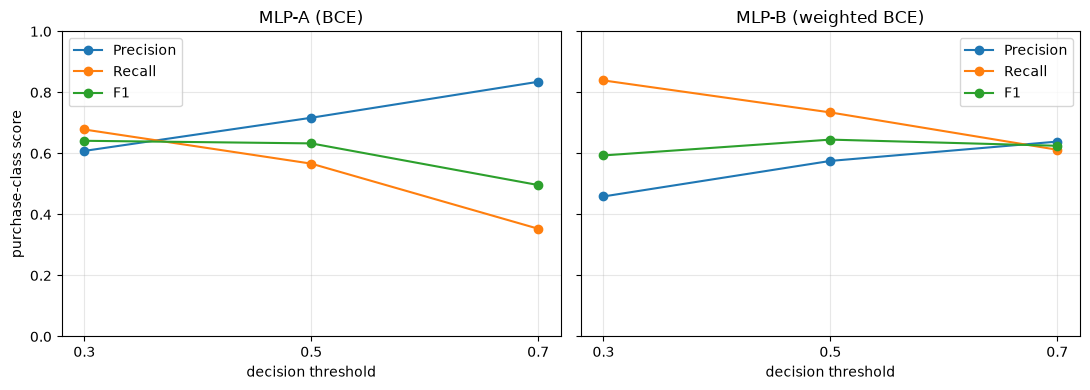

In [25]:
# [공통] 성능 변화 그래프 기본 틀
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, part) in zip(axes, threshold_df.groupby("Model", sort=False)):
    for metric in ["Precision", "Recall", "F1"]:
        # TODO 7-4. threshold를 x축으로 지표의 변화를 표시합니다.
        # 힌트: ax.plot(part["Threshold"], part[metric], marker="o", label=metric)
        ax.plot(part["Threshold"], part[metric], marker="o", label=metric)  # 임계값별 지표 표시
    ax.set_title(name)
    ax.set_xticks(thresholds)
    ax.set_xlabel("decision threshold")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("purchase-class score")
plt.tight_layout()
plt.show()

**그래프 해석:** 두 모델 모두 임계값이 높아질수록 Recall이 낮아지고, 이 결과에서는 Precision이 높아졌다. F1은 두 지표가 함께 달라지는 정도에 따라 변하므로 임계값과 목적을 함께 고려한다.


### ⑦-4. 최종 MLP, 임계값 선택 — TODO

In [ ]:
# TODO 7-5. Validation F1, Recall, Precision 내림차순으로 정렬합니다.
# 힌트: sort_values([...], ascending=False).reset_index(drop=True)
ranked = threshold_df.sort_values(
    ["F1", "Recall", "Precision"], ascending=False
).reset_index(drop=True)  # 기본 A/B 검증 성능순 정렬
display(ranked[["Model", "Threshold", "F1", "Precision", "Recall", "FP", "FN"]].round(3))

# TODO 7-6. 결과를 바탕으로 최종 MLP 이름과 분류 임계값을 직접 지정합니다.
# 모델명: "MLP-A (BCE)" 또는 "MLP-B (weighted BCE)"
# 임계값: 0.3, 0.5, 0.7 중 하나
# Test 결과를 확인하기 전에 결정합니다.
# 추가 가중치 실험까지 고려해 가중치 절반 모델을 선택합니다.
selected_row = weight_experiment_df.loc[
    (weight_experiment_df["설정"] == "비율의 절반")
    & (weight_experiment_df["임계값"] == 0.5)
].iloc[0]  # Validation 실험에서 정한 설정
SELECTED_MODEL_NAME = "MLP-B (half weighted BCE)"  # 최종 모델
SELECTED_THRESHOLD = 0.5  # 선택한 임계값
SELECTED_EPOCHS = int(selected_row["최고 epoch (0.5)"])  # 검증 최고 에포크
SELECTED_WEIGHT_FACTOR = 0.5  # 구매 클래스 비율의 절반
print("선택 모델:", SELECTED_MODEL_NAME)
print("선택 임계값:", SELECTED_THRESHOLD)
print("재학습 에포크:", SELECTED_EPOCHS)
print("Validation F1:", round(selected_row["F1"], 3))


,Model,Threshold,F1,Precision,Recall,FP,FN
0,MLP-B (weighted BCE),0.5,0.645,0.575,0.734,155,76
1,MLP-A (BCE),0.3,0.641,0.608,0.678,125,92
2,MLP-A (BCE),0.5,0.633,0.717,0.566,64,124
3,MLP-B (weighted BCE),0.7,0.625,0.639,0.612,99,111
4,MLP-B (weighted BCE),0.3,0.593,0.459,0.839,283,46
5,MLP-A (BCE),0.7,0.496,0.835,0.353,20,185


선택 모델: MLP-B (half weighted BCE)
선택 임계값: 0.5
재학습 에포크: 16
Validation F1: 0.657


**선택:** 가중치 절반, 임계값 0.5 모델의 Validation F1은 0.657로 기본 MLP-B의 0.645보다 높았다. 다섯 분할 비교에서도 가중치 절반의 평균 F1은 0.659, 기본 B는 0.627이었다. F1을 우선하는 기준에 따라 가중치 절반 모델을 선택한다.

**한계:** 다섯 분할의 학습 데이터는 서로 겹치고, 가중치 절반은 기본 B보다 구매를 더 놓쳤다. 선택한 에포크와 임계값은 Validation 실험을 기준으로 정한다.


**[CP-07] 완료 기준:** MLP별 FP, FN과 임계값별 성능을 비교하고 최종 모델, 임계값을 지정합니다.

**의사결정 ④:** 선택 근거를 `adr.md`에 기록합니다. **선택 심화:** PR 곡선 분석.

---
## ⑧ 최종 실행 확인 및 프로젝트 제출 — CP-08

**목표:** 아래 공통 코드를 실행하고, 분석 문서, 명세서, GitHub 제출을 완료합니다. **새로운 개발 TODO는 없습니다.**

### ⑧-1. 선택 모델 재학습 — 공통 코드


In [ ]:
# [공통] 선택한 구조, 손실, 에포크 수를 고정하여 Train+Validation으로 재학습합니다.
X_trainval = pd.concat([X_train, X_valid])  # 학습과 검증 입력 합치기
y_trainval = pd.concat([y_train, y_valid])  # 학습과 검증 정답 합치기
final_preprocessor = make_preprocessor()  # 전처리 새로 생성
Xt_trainval = np.asarray(
    final_preprocessor.fit_transform(X_trainval), dtype=np.float32
)  # 합친 데이터로 전처리 학습
Xt_test = np.asarray(
    final_preprocessor.transform(X_test), dtype=np.float32
)  # Test는 같은 기준으로 변환

final_ds = TensorDataset(
    torch.from_numpy(Xt_trainval),
    torch.tensor(y_trainval.to_numpy(), dtype=torch.float32),
)  # 재학습 입력과 정답
half_weight = (
    float((y_trainval == 0).sum() / (y_trainval == 1).sum())
    * SELECTED_WEIGHT_FACTOR
)  # 구매 클래스 비율의 절반
half_model = make_mlp(Xt_trainval.shape[1])  # 최종 구조와 시드
half_loader = DataLoader(
    final_ds,
    batch_size=256,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)  # 미니배치 준비
half_loss = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(half_weight, dtype=torch.float32)
)  # 선택한 구매 가중치
half_optimizer = torch.optim.Adam(
    half_model.parameters(), lr=0.001
)  # 기존 학습률 사용
for epoch in range(SELECTED_EPOCHS):
    train_one_epoch(half_model, half_loader, half_loss, half_optimizer)  # 재학습
half_model.eval()  # 예측 모드
RESULTS_DIR = Path("../results")  # 결과 저장 경로
RESULTS_DIR.mkdir(parents=True, exist_ok=True)  # 결과 폴더 준비
print("선택 모델:", SELECTED_MODEL_NAME)
print("Train+Validation:", len(X_trainval), "행 / 에포크:", SELECTED_EPOCHS)
print("구매 가중치:", round(half_weight, 3))


선택 모델: MLP-B (half weighted BCE)
Train+Validation: 10480 행 / 에포크: 16
구매 가중치: 2.731


**결과 해석:** 선택한 가중치 절반 모델을 Train과 Validation 10,480건으로 16에포크 재학습했다. 합친 데이터의 클래스 비율 절반은 약 2.731이다. Train에 없던 `TrafficType=17`을 추가로 학습해 입력은 74열이 됐다.


### ⑧-2. 선택한 모델의 Test 평가 — 공통 코드


In [ ]:
# [공통] 선택한 모델의 Test 성능을 평가합니다.
half_pred = (
    mlp_probabilities(half_model, Xt_test) >= SELECTED_THRESHOLD
).astype(int)  # 선택한 임계값으로 분류
half_scores = classification_scores(y_test, half_pred)  # 구매 클래스 지표
half_cm = pd.DataFrame(
    confusion_matrix(y_test, half_pred, labels=[0, 1]),
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"],
)  # 실제 결과와 예측 결과
print("Test 지표")
for metric, value in half_scores.items():
    print(f"{metric:<12}{value:.3f}")  # 지표별 결과
print("Test 혼동행렬")
display(half_cm)


Test 지표
Accuracy    0.884
Precision   0.603
Recall      0.724
F1          0.658
Test 혼동행렬


,Predicted 0,Predicted 1
Actual 0,1428,136
Actual 1,79,207


**결과 해석:** 이번 Test 1,850건에서 정확도는 0.884, 정밀도는 0.603, 재현율은 0.724, F1은 0.658이다. 실제 구매 286건 중 207건을 찾고 79건을 놓쳤으며, 미구매 136건을 구매로 잘못 예측했다.

**평가 이력:** 이 Test는 이전에 확인하고 모델 비교에도 사용했으므로, 위 점수를 새 데이터에 대한 독립적인 최종 평가로 해석할 수 없다. 새로운 데이터의 성능은 확인하지 않았다.


### ⑧-3. 기본 모델 비교 CSV 저장 — 공통 코드

이 두 표는 기본 모델과 MLP-A/B의 비교 결과다. 가중치 절반 모델의 실험 결과는 CP-06 표에서 확인한다.


In [30]:
# [공통] 최종 Test 결과는 Notebook과 Analysis에만 기록합니다(별도 Test CSV 없음).
results_df.round(4).to_csv(RESULTS_DIR / "02_model_comparison.csv", index=False)
threshold_df.round(4).to_csv(RESULTS_DIR / "02_threshold_comparison.csv", index=False)
print("저장한 결과 파일:")
for p in sorted(RESULTS_DIR.glob("02_*")):
    print("-", p.name)

저장한 결과 파일:
- 02_final_classifier.joblib
- 02_model_comparison.csv
- 02_model_config.json
- 02_threshold_comparison.csv


**비교표 설명:** 저장한 두 CSV는 기본 모델과 MLP-A/B의 Validation 비교 결과다. 최종 모델의 가중치 실험 결과는 CP-06에 기록했다.


### 최종 모델 선택과 저장

Validation F1과 추가 분할 비교를 근거로 가중치 절반 모델, 임계값 0.5를 선택했다. Test 점수는 선택 근거에 포함하지 않는다. 기존 Test 확인 및 비교 이력이 있으므로 독립적인 새 데이터로 평가한 점수는 아니다.


In [ ]:
# 최종 모델 저장: 추가 실험에서 선택한 가중치 절반 모델
final_model = half_model  # 최종 모델로 지정
final_model.eval()  # 예측 모드

model_bundle = {
    "preprocessor": final_preprocessor,  # Train + Validation으로 학습한 전처리
    "model_state_dict": {
        key: value.detach().cpu().clone()
        for key, value in final_model.state_dict().items()
    },  # 학습된 가중치
    "input_dim": int(Xt_trainval.shape[1]),  # 전처리 후 입력 열 수
}
config = {
    "model_name": "MLP-B (half weighted BCE)",
    "decision_threshold": SELECTED_THRESHOLD,
    "positive_class": 1,
    "features": FEATURES,
    "network": {"hidden_units": [64, 32], "dropout": 0.1},
    "training": {
        "epochs": SELECTED_EPOCHS,
        "weighted_loss": True,
        "weight_factor": SELECTED_WEIGHT_FACTOR,
        "pos_weight": half_weight,
        "seed": SEED,
    },
}  # 선택한 설정 기록

RESULTS_DIR = Path("../results")  # 결과 저장 경로
RESULTS_DIR.mkdir(parents=True, exist_ok=True)  # 결과 폴더 준비
MODEL_PATH = RESULTS_DIR / "02_final_classifier.joblib"
CONFIG_PATH = RESULTS_DIR / "02_model_config.json"
joblib.dump(model_bundle, MODEL_PATH, compress=3)  # 전처리와 모델 저장
CONFIG_PATH.write_text(
    json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8"
)  # 최종 설정 저장

loaded_bundle = joblib.load(MODEL_PATH)  # 저장한 모델 불러오기
loaded_config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))  # 설정 불러오기
loaded_mlp = PurchaseMLP(
    input_dim=loaded_bundle["input_dim"],
    dropout=loaded_config["network"]["dropout"],
)  # 같은 구조 생성
loaded_mlp.load_state_dict(loaded_bundle["model_state_dict"])  # 학습된 가중치 복원
loaded_mlp.eval()  # 예측 모드
loaded_test = np.asarray(
    loaded_bundle["preprocessor"].transform(X_test), dtype=np.float32
)  # 저장한 기준으로 Test 변환
loaded_pred = (
    mlp_probabilities(loaded_mlp, loaded_test) >= loaded_config["decision_threshold"]
).astype(int)  # 저장된 임계값으로 분류
print("최종 모델:", loaded_config["model_name"])
print("학습 에포크:", loaded_config["training"]["epochs"])
print("구매 가중치:", round(loaded_config["training"]["pos_weight"], 3))
print("저장 전후 예측 일치:", np.array_equal(half_pred, loaded_pred))
print("Test F1:", round(classification_scores(y_test, loaded_pred)["F1"], 3))


최종 모델: MLP-B (half weighted BCE)
학습 에포크: 16
구매 가중치: 2.731
저장 전후 예측 일치: True
Test F1: 0.658


**결과 해석:** 최종 모델을 저장한 뒤 불러와 Test 1,850건의 예측이 저장 전과 모두 같은 것을 확인했다. 이번 Test F1은 0.658이며 다른 데이터에서도 비슷한 성능을 내는지는 추가 확인이 필요하다.


### 최종 모델의 구매 여부 예측 확인


In [ ]:
# [공통] 새 세션 1건의 원본 특성 → 저장된 전처리 → PyTorch 확률 → 임계값 판정

def predict_purchase(loaded_bundle, loaded_mlp, config, record):
    row = pd.DataFrame([record])[config["features"]]  # 학습 때의 입력 열 순서 유지
    transformed = np.asarray(loaded_bundle["preprocessor"].transform(row), dtype=np.float32)
    probability = float(mlp_probabilities(loaded_mlp, transformed)[0])  # 한 건의 Sigmoid 점수
    return {
        "purchase_probability": round(probability, 4),
        "prediction": int(probability >= config["decision_threshold"]),
        "threshold": float(config["decision_threshold"]),
    }

example = X_test.iloc[0].to_dict()  # Test 첫 행으로 사용 예 확인
print("예측:", predict_purchase(loaded_bundle, loaded_mlp, loaded_config, example))
print("실제 Revenue:", int(y_test.iloc[0]))

예측: {'purchase_probability': 0.0047, 'prediction': 0, 'threshold': 0.5}
실제 Revenue: 0


**결과 해석:** 최종 모델로 첫 번째 Test 방문을 예측한 점수는 0.0047이다. 임계값 0.5보다 낮아 미구매(0)로 예측했고 실제 정답도 0이다. 가중 손실 모델의 Sigmoid 점수가 실제 구매 확률로 정확하게 보정되었는지는 확인하지 않았다.


**[CP-08] 완료 기준:** 선택한 모델의 Test 평가, 재로딩과 예측을 확인합니다.

**결과 파일 4개:** `02_final_classifier.joblib`, `02_model_config.json`, `02_model_comparison.csv`, `02_threshold_comparison.csv`

**확인:** 이 Test는 이전에 확인과 모델 비교에 사용했다. 새로운 데이터의 성능은 확인하지 않았다.
